## Intermittency / bout-index analysis

Defines the intermittency index (eta) from speed and bout duration. Produces max-speed-onset and target-speed plots across eta. 

Figures are saved to the project `figures/` directory and to `intermittency_index/media/`.

Import libraries:

In [2]:
# --- Imports and path setup (paths from code/paths.py) ---
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
import sys
from pathlib import Path
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import PROJECT_ROOT, DATA_DIR, FIGURES_DIR, notebook_media_dir

%load_ext autoreload
%autoreload 2
from functions.utilities import *
from functions.freely_swimming import *
from functions.MC_freely_swimming import *
from functions.MC_plots import *
from functions.MC_utilities import *

import os
import h5py
from ipywidgets import interact, IntSlider
from scipy import fft
from scipy.ndimage import gaussian_filter
from skimage import io
import pickle
from sklearn.preprocessing import scale
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from scipy.stats import iqr
import pandas as pd
from scipy.interpolate import interp1d
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [3]:
from functions.MC_utilities import *
[color_y, color_m, color_o, color_low_boutID, color_med_boutID, color_high_boutID, color_cont, color_bout] = get_colors()
group_colors = [color_y, color_m, color_o]

In [4]:
print(os.getcwd()) 

<repo>/code/intermittency_index


In [5]:
# Paths from code/paths.py (project root, data, figures, local media)
path = str(PROJECT_ROOT)
path_data = str(DATA_DIR)
path_figures = str(FIGURES_DIR)
path_media = str(notebook_media_dir("intermittency_index"))
print(path, path_data, path_figures)

<repo> <repo>/data <repo>/figures


#### Import data:

In [6]:
#fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_27Mar24_1','14_31Oct24_1']
fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_31Oct24_1']
index_y = list(range(0, len(fish_ids_young)))
print(index_y)

[0, 1, 2, 3]


In [7]:
fish_ids_intermediate=['17_21May24_2','18_22May24_1','18_22May24_2','19_23May24_5','20_05Jun24_1','20_05Jun24_2','20_12Jun24_1','21_06Dec24_1','21_06Dec24_2','21_06Jun24_1','25_10Jun24_1']
index_i = list( range(len(fish_ids_young), len(fish_ids_young)+len(fish_ids_intermediate)) )
print(index_i)

[4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]


In [8]:
#fish_ids_old=['26_02May24_2','27_12Jun24_1','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
fish_ids_old=['26_02May24_2','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
index_o = list( range( len(fish_ids_young)+len(fish_ids_intermediate) , len(fish_ids_young)+len(fish_ids_intermediate)+len(fish_ids_old) ) )
print(index_o)

[15, 16, 17, 18, 19]


In [9]:
fish_ids=fish_ids_young+fish_ids_intermediate+fish_ids_old

In [10]:
fish_ids

['13_06May24_1',
 '13_30Oct24_3',
 '13_30Oct24_4',
 '14_31Oct24_1',
 '17_21May24_2',
 '18_22May24_1',
 '18_22May24_2',
 '19_23May24_5',
 '20_05Jun24_1',
 '20_05Jun24_2',
 '20_12Jun24_1',
 '21_06Dec24_1',
 '21_06Dec24_2',
 '21_06Jun24_1',
 '25_10Jun24_1',
 '26_02May24_2',
 '28_04May24_1',
 '30_06May24_2',
 '34_11Dec24_1',
 '34_11Dec24_3']

In [11]:
index_groups = {
    '1-2 wpf': index_y,
    '3 wpf': index_i,
    '4-5 wpf': index_o
}

In [12]:
age_list = [int(fid.split('_')[0]) for fid in fish_ids]
print(age_list)

[13, 13, 13, 14, 17, 18, 18, 19, 20, 20, 20, 21, 21, 21, 25, 26, 28, 30, 34, 34]


Load:

In [13]:
speed_clean = pd.read_hdf(os.path.join(path_data, f"speed_clean.h5"), key='df')

In [14]:
speed_clean

,ID,t_c,vfish_c,vtail_c,dangletail_c,angletail_c,freqtail_c,mean_thrust_c
0,13_06May24_1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,13_06May24_1,0.003333,NaN,NaN,NaN,NaN,NaN,NaN
2,13_06May24_1,0.006667,NaN,NaN,NaN,NaN,NaN,NaN
3,13_06May24_1,0.010000,NaN,NaN,NaN,NaN,NaN,NaN
4,13_06May24_1,0.013333,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
21727813,34_11Dec24_3,320.736667,NaN,NaN,NaN,NaN,NaN,NaN
21727814,34_11Dec24_3,320.740000,NaN,NaN,NaN,NaN,NaN,NaN
21727815,34_11Dec24_3,320.743333,NaN,NaN,NaN,NaN,NaN,NaN
21727816,34_11Dec24_3,320.746667,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
thrust_thresholds = pd.read_hdf(os.path.join(path_data, f"thrust_thresholds.h5"), key='df')

In [16]:
thrust_thresholds

,ID,thrust_thr,mask_movetail
0,13_06May24_1,0.000331,False
1,13_06May24_1,0.000331,False
2,13_06May24_1,0.000331,False
3,13_06May24_1,0.000331,False
4,13_06May24_1,0.000331,False
...,...,...,...
21727813,34_11Dec24_3,0.025991,False
21727814,34_11Dec24_3,0.025991,False
21727815,34_11Dec24_3,0.025991,False
21727816,34_11Dec24_3,0.025991,False


In [17]:
onsets = pd.read_hdf(os.path.join(path_data, f"onsets.h5"), key='df')

In [18]:
onsets

,ID,onset_indices,initial_vfish,initial_vtail,bout_duration
0,13_06May24_1,1369,6.717492,102.127655,2.566667
1,13_06May24_1,2987,4.772649,90.986139,1.966667
2,13_06May24_1,4877,7.283671,136.008985,1.780000
3,13_06May24_1,5695,6.163918,100.164392,2.900000
4,13_06May24_1,6601,3.750249,69.222574,0.966667
...,...,...,...,...,...
45480,34_11Dec24_3,92811,24.794113,263.748909,0.213333
45481,34_11Dec24_3,92984,35.093076,348.691133,0.213333
45482,34_11Dec24_3,93206,38.267398,332.921438,0.196667
45483,34_11Dec24_3,93407,35.724430,275.439541,0.216667


In [19]:
t_c_list=[]
vfish_c_list=[]
vtail_c_list=[]
mean_thrust_c_list=[]
angletail_c_list=[]
dangletail_c_list=[]
freqtail_c_list=[]

for fish_ID in tqdm(fish_ids):
    speed_clean_fish=subset_by_fish(fish_ID,DF1=speed_clean)[0]
    t_c_list.append(speed_clean_fish['t_c'].values)
    vfish_c_list.append(speed_clean_fish['vfish_c'].values)
    vtail_c_list.append(speed_clean_fish['vtail_c'].values)    
    mean_thrust_c_list.append(speed_clean_fish['mean_thrust_c'].values)
    angletail_c_list.append(speed_clean_fish['angletail_c'].values)
    dangletail_c_list.append(speed_clean_fish['dangletail_c'].values)
    freqtail_c_list.append(speed_clean_fish['freqtail_c'].values)

  0%|          | 0/20 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▌         | 1/20 [00:02<00:56,  2.99s/it]

Subsetting data of the fish 13_30Oct24_3


 10%|█         | 2/20 [00:05<00:51,  2.88s/it]

...

 90%|█████████ | 18/20 [00:52<00:05,  2.96s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 19/20 [00:55<00:02,  2.91s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 20/20 [00:58<00:00,  2.92s/it]


In [20]:
thrust_thr_list=[]
mask_movetail_list=[]

for fish_ID in tqdm(fish_ids):
    thrust_thresholds_fish=subset_by_fish(fish_ID,DF1=thrust_thresholds)[0]
    thrust_thr_list.append(thrust_thresholds_fish['thrust_thr'].values[0])
    mask_movetail_list.append(thrust_thresholds_fish['mask_movetail'].values)

  0%|          | 0/20 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▌         | 1/20 [00:02<00:56,  2.95s/it]

Subsetting data of the fish 13_30Oct24_3


 10%|█         | 2/20 [00:05<00:50,  2.78s/it]

...

 90%|█████████ | 18/20 [00:50<00:05,  2.78s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 19/20 [00:53<00:02,  2.78s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 20/20 [00:55<00:00,  2.79s/it]


In [21]:
onset_indices_list=[]
initial_vfish_list=[]
initial_vtail_list=[]
bout_duration_list=[]
onset_times_list=[]

for fish_ID in tqdm(fish_ids):
    onsets_fish=subset_by_fish(fish_ID,DF1=onsets)[0]
    onset_indices_list.append(onsets_fish['onset_indices'].values)
    initial_vfish_list.append(onsets_fish['initial_vfish'].values)
    initial_vtail_list.append(onsets_fish['initial_vtail'].values)
    bout_duration_list.append(onsets_fish['bout_duration'].values)
    
for i in range(len(fish_ids)):  
    onset_times_list.append(t_c_list[i][onset_indices_list[i]])

100%|██████████| 20/20 [00:00<00:00, 154.31it/s]

Subsetting data of the fish 13_06May24_1
Subsetting data of the fish 13_30Oct24_3
Subsetting data of the fish 13_30Oct24_4
Subsetting data of the fish 14_31Oct24_1
Subsetting data of the fish 17_21May24_2
Subsetting data of the fish 18_22May24_1
Subsetting data of the fish 18_22May24_2
Subsetting data of the fish 19_23May24_5
Subsetting data of the fish 20_05Jun24_1
Subsetting data of the fish 20_05Jun24_2
Subsetting data of the fish 20_12Jun24_1
Subsetting data of the fish 21_06Dec24_1
Subsetting data of the fish 21_06Dec24_2
Subsetting data of the fish 21_06Jun24_1
Subsetting data of the fish 25_10Jun24_1
Subsetting data of the fish 26_02May24_2
Subsetting data of the fish 28_04May24_1
Subsetting data of the fish 30_06May24_2
Subsetting data of the fish 34_11Dec24_1
Subsetting data of the fish 34_11Dec24_3


# define eta

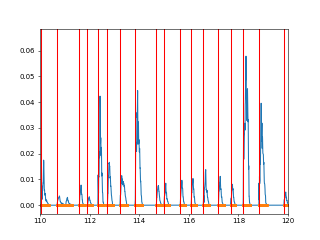

In [35]:
i=13
dt=1/300
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=50)
#ax.plot(t_c_list[i],vtail_c_list[i]/1000,'-')
#ax.plot(t_c_list[i],angletail_c_list[i]/10,'-')
ax.plot(t_c_list[i],mean_thrust_c_list[i],'-')
#ax.axhline(thrust_thr_list[i],c='k')
ax.plot(t_c_list[i][mask_movetail_list[i]], np.zeros(np.sum(mask_movetail_list[i])),'.')

#ax.plot(t_c_list[i],mask_movetail_list[i]/10,'-', alpha = 0.5)

for n in range(onset_indices_list[i].shape[0]):
    ax.axvline(onset_times_list[i][n],c='red', linestyle='-')

ax.set_xlim(110,120)
plt.show()

Fraction of bouts for all fish: [0.1518987341772152, 0.19704433497536947, 0.17964071856287425, 0.3268765133171913, 0.746031746031746, 0.3642681929681112, 0.452070775811783, 0.44605504587155964, 0.17635658914728683, 0.3460490463215259, 0.8301520543513426, 0.6227495908346972, 0.6063348416289592, 0.6630620375640296, 0.4380069524913094, 0.9374355448607768, 0.9882352941176471, 0.5227272727272727, 0.9410898379970545, 0.8450704225352113]


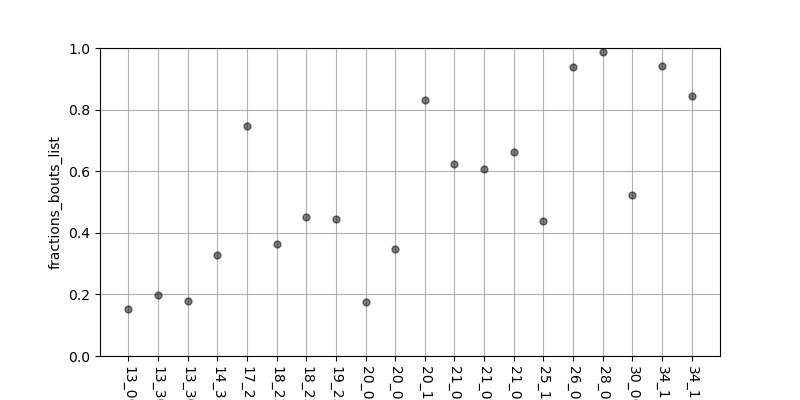

In [36]:
fractions_bouts_list = []

for i in range(len(fish_ids)):
    valid_swimming_events = []
    valid_bouts = []
    onset_indices = onset_indices_list[i]
    bout_duration = bout_duration_list[i]
    mask_movetail = mask_movetail_list[i]
    vtail = vtail_c_list[i]
    t_c = t_c_list[i]
    
    for n in range(len(onset_indices) - 1):
        
        #idx0, idx1 = int(onset_indices[n]), int(onset_indices[n+1])
        #t0, t1 = t_c[idx0], t_c[idx1]
        idx0, idx1 = int(onset_indices[n]), int(onset_indices[n] + bout_duration[n]/dt)
        t0, t1 = t_c[idx0], t_c[idx1] 
 
        segment = vtail[idx0:idx1]
        if len(segment) == 0:
            continue 
        nan_ratio = np.sum(np.isnan(segment)) / len(segment)
        
        if nan_ratio <= 0.8: #at least 50% non nan values
            valid_swimming_events.append(t1 - t0)
            sum = np.sum(mask_movetail[idx0:idx1])*dt
            if sum < 0.36:  #th
                valid_bouts.append(t1 - t0)
 

    total_bouts = len(valid_bouts)#np.sum(valid_bouts) #
    total_swimming_events = len(valid_swimming_events)#np.sum(valid_swimming_events) #

    fraction_bouts = total_bouts / total_swimming_events #if count_swimming_events > 0 else 0
    fractions_bouts_list.append(fraction_bouts)
print("Fraction of bouts for all fish:", fractions_bouts_list)
   
fig, ax = plt.subplots(figsize=(8, 4))
plt.plot(fish_ids, fractions_bouts_list, 'o', color='black', markersize=5, alpha=0.5)
plt.xticks(rotation=-90)
plt.ylabel('fractions_bouts_list')
plt.xlabel('fish ID')
plt.ylim(0,1)
plt.grid()
plt.show()


fractions_bouts_list = np.array(fractions_bouts_list)

In [37]:
np.sum(fractions_bouts_list<=0.20)

4

In [38]:
np.sum((fractions_bouts_list > 0.2) & (fractions_bouts_list < 0.8))

11

In [39]:
np.sum(fractions_bouts_list>=0.80)

5

In [40]:
fish_ids = np.array(fish_ids)
idx_low_eta=np.where(fractions_bouts_list<=0.20)
print(fish_ids[idx_low_eta])
print(idx_low_eta)
print(len(idx_low_eta[0]))

['13_06May24_1' '13_30Oct24_3' '13_30Oct24_4' '20_05Jun24_1']
(array([0, 1, 2, 8]),)
4


In [41]:
idx_mid_eta=np.where((fractions_bouts_list > 0.2) & (fractions_bouts_list < 0.8))
print(fish_ids[idx_mid_eta])
print(idx_mid_eta)
print(len(idx_mid_eta[0]))

['14_31Oct24_1' '17_21May24_2' '18_22May24_1' '18_22May24_2'
 '19_23May24_5' '20_05Jun24_2' '21_06Dec24_1' '21_06Dec24_2'
 '21_06Jun24_1' '25_10Jun24_1' '30_06May24_2']
(array([ 3,  4,  5,  6,  7,  9, 11, 12, 13, 14, 17]),)
11


In [42]:
idx_high_eta=np.where(fractions_bouts_list>=0.80)
print(fish_ids[idx_high_eta])
print(idx_high_eta)
print(len(idx_high_eta[0]))


['20_12Jun24_1' '26_02May24_2' '28_04May24_1' '34_11Dec24_1'
 '34_11Dec24_3']
(array([10, 15, 16, 18, 19]),)
5


In [43]:
index_cont = [0, 1, 2, 8]
index_mix = [3, 4, 5, 6, 7, 9, 11, 12, 13, 14, 17]
index_bout = [10, 15, 16, 18, 19]

In [44]:
fractions_bouts_list[index_cont]

array([0.15189873, 0.19704433, 0.17964072, 0.17635659])

In [45]:
fractions_bouts_list[index_mix]

array([0.32687651, 0.74603175, 0.36426819, 0.45207078, 0.44605505,
       0.34604905, 0.62274959, 0.60633484, 0.66306204, 0.43800695,
       0.52272727])

In [46]:
fractions_bouts_list[index_bout]


array([0.83015205, 0.93743554, 0.98823529, 0.94108984, 0.84507042])

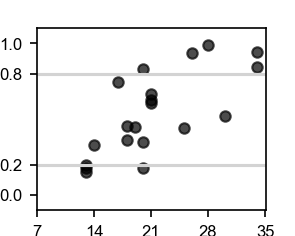

In [47]:
default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 5
fig_height_cm = 4

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)
age = [int(first_id.split('_')[0][:2]) for first_id in fish_ids]

plt.plot(age, (fractions_bouts_list), 'o', color='black', markersize=5, alpha=0.7)

plt.axhline(0.2, color='lightgray')
plt.axhline(0.8, color='lightgray')
plt.ylabel(r'intermittency index $\eta$')
plt.xlabel('age (dpf)')
plt.ylim(-0.1,1.1)

plt.yticks([0,0.2, 0.8, 1])
plt.xticks([7, 14, 21, 28, 35])
#fig.savefig(os.path.join(path_figures, "fraction_of_bout_age.pdf"), format="pdf")

plt.show()

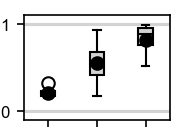

In [48]:
default()
widget()
arial()

fig, ax = plt.subplots(figsize=(3.2 / 2.54, 2.3/ 2.54), dpi=150)  # single axis

age = np.array([int(first_id.split('_')[0][:2]) for first_id in fish_ids])
eta = np.array((fractions_bouts_list))#np.array(normalize_y(fractions_bouts_list))#np.array(normalize_y(fractions_bouts_list))#np.array((fractions_bouts_list))#np.array(normalize_y(fractions_bouts_list))

# Grouping
young_eta = eta[age < 17]
middle_eta = eta[(age >= 17) & (age <= 26)]
old_eta = eta[age > 26]

# Labels and data for boxplot
group_labels = ['1-2', '3', '4-5']
data = [young_eta, middle_eta, old_eta]


ax.axhline(0, color='lightgray')
ax.axhline(1, color='lightgray')

bp = ax.boxplot(data, patch_artist=True, showmeans=True,
                boxprops=dict(facecolor='lightgray', color='black'),
                medianprops=dict(color='black'),
                meanprops=dict(marker='o', markerfacecolor='black', markeredgecolor='black'))


#ax.axhline(0.2, color='lightgray')
#ax.axhline(0.8, color='lightgray')

# Aesthetic
ax.set_ylabel(r'$\eta$')
ax.set_xticks([1, 2, 3])
ax.set_xlabel('age (wpf)')
ax.set_xticklabels(group_labels)
ax.set_ylim(-0.1, 1.1)
ax.set_yticks([0, 1])

plt.savefig(os.path.join(path_media,f'Fig_1h_boxplot_intermittency_index.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,'Fig_1h_boxplot_intermittency_index.pdf'),format = 'pdf')

#plt.tight_layout()
plt.show()

# Sort data using eta

In [49]:
initial_vfish_median_list = []
initial_vfish_iqm_list = []
initial_vfish_iqp_list = []

for i in range(len(fish_ids)):
    data = initial_vfish_list[i]

    median_val = np.nanquantile(data, 0.5)
    iqp_val = np.nanquantile(data, 0.75) - median_val
    iqm_val = median_val - np.nanquantile(data, 0.25)

    initial_vfish_median_list.append(median_val)
    initial_vfish_iqm_list.append(iqm_val)
    initial_vfish_iqp_list.append(iqp_val)

# Convert to arrays for plotting
vi_med = np.array(initial_vfish_median_list)
vi_iqm = np.array(initial_vfish_iqm_list)
vi_iqp = np.array(initial_vfish_iqp_list)

# yerr shape must be (2, N)
yerr = np.vstack([vi_iqm, vi_iqp])
    

In [50]:
from scipy.optimize import curve_fit

# Define exponential model: y = a * exp(b * x)
def exp_model(x, a, b):
    return a * np.exp(b * x)


1-2 wpf
3 wpf
4-5 wpf
Exponential fit: y = 2.125·exp(2.405·x)


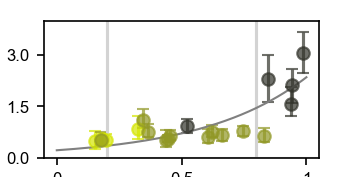

In [51]:
default()
widget()
arial()
# --- Plot setup ---
cm_to_inch = 1 / 2.54
fig_width_cm = 6
fig_height_cm = 3

fig, ax = plt.subplots(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)

all_x = []
all_y = []

j = 0
for group_name, indices in index_groups.items():
    color = group_colors[j]
    print(group_name)

    y = [vi_med[i] for i in indices]
    norm_fractions_bouts_array = (fractions_bouts_list)
    x = [norm_fractions_bouts_array[i] for i in indices]
    yerr = np.array([
        [vi_iqm[i] for i in indices],
        [vi_iqp[i] for i in indices]
    ])

    ax.errorbar(
        x, y,
        yerr=yerr,
        fmt='o',
        color=color,
        ecolor=color,
        elinewidth=1.5,
        capsize=3,
        label=group_name,
        alpha=0.7
    )
    
    #ax.axvline(x=0.2, linestyle='-')
    #ax.axvline(x=0.8, linestyle='-')

    all_x.extend(x)
    all_y.extend(y)
    j += 1

ax.axhline(0, color='lightgray')
#ax.axvline(0, color='lightgray')
ax.axvline(0.2, color='lightgray')
ax.axvline(0.8, color='lightgray')
#ax.axvline(1, color='lightgray')

# --- Exponential fit ---
idx_bout = np.array(all_x)
v_max = np.array(all_y)

# Initial guess for a and b
initial_guess = [1.0, 1.0]

try:
    popt, pcov = curve_fit(exp_model, idx_bout, v_max, p0=initial_guess)
    a, b = popt
    print(f"Exponential fit: y = {a:.3f}·exp({b:.3f}·x)")

    x_fit = np.linspace(0, 1, 200)
    y_fit = exp_model(x_fit, *popt)
    ax.plot(x_fit, y_fit, '-',  color='gray', linewidth=1, label='best fit')
  

except RuntimeError:
    print("❌ Exponential fit did not converge.")

# --- Final formatting ---
ax.set_ylabel(r'$v$ (cm/s)')
ax.set_xlabel(r'intermittency index $\eta$')
ax.set_xticks([0, 0.5, 1], [0, 0.5, 1])

ax.set_yticks([0, 15, 30], [0.0, 1.5, 3.0])
ax.set_ylim([0, 40])
#ax.legend()
#plt.tight_layout()

fig.savefig(os.path.join(path_figures, "Fig_S7b_speed_onset_eta_all_fish.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_S7b_speed_onset_eta_all_fish.pdf"), format="pdf", bbox_inches='tight', dpi=200)

plt.show()

In [52]:
# --- Colors for groups ---
color_low_eta = '#dc267f'
color_medium_eta = '#fe6100'
color_high_eta = '#ffb000'

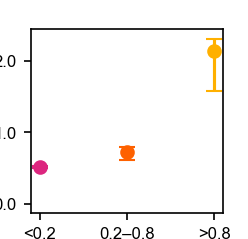

In [56]:
# --- Divide into 3 groups based on x thresholds ---
group1 = [y for x, y in zip(all_x, all_y) if x < 0.2]
group2 = [y for x, y in zip(all_x, all_y) if 0.2 <= x <= 0.8]
group3 = [y for x, y in zip(all_x, all_y) if x > 0.8]

groups = [group1, group2, group3]
positions = [0, 1, 2]
labels = ['<0.2', '0.2–0.8', '>0.8']
colors = [color_low_eta, color_medium_eta, color_high_eta]

# --- Compute median and IQR-based error bars ---
medians = [np.nanquantile(g, 0.5) for g in groups]
iqr_lower = [np.nanquantile(g, 0.5) - np.nanquantile(g, 0.25) for g in groups]
iqr_upper = [np.nanquantile(g, 0.75) - np.nanquantile(g, 0.5) for g in groups]

default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 4.2
fig_height_cm = 4.05

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch),   dpi=150)

ax = fig.add_subplot(111)

for x, y, lo, up, c in zip(
    positions, medians, iqr_lower, iqr_upper, colors
):
    ax.errorbar(
        x, y,
        yerr=[[lo], [up]],
        fmt='o',
        capsize=4,
        color=c,
        ecolor=c
    )

plt.ylim(-1.1646799117787212, 24.458278147353145)
plt.yticks([0, 10, 20], ['0.0', '1.0', '2.0']) #cm/s
#ax.set_xlim(-0.5, 2.5)
ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_ylabel(r'$v_{f}^{\mathrm{Max}} (\mathrm{cm/s})$')
ax.set_xlabel(r'$\eta$')
#ax.set_ylim(0, max(all_y) * 1.1)

fig.savefig(os.path.join(path_figures, "Fig_3c_max_speed_onset_vs_eta.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_3c_max_speed_onset_vs_eta.pdf"), format="pdf", bbox_inches='tight', dpi=200)

plt.show()

## Target speed

In [44]:
vfish_median_list = []
vfish_mean_list = []
vfish_std_list = []
vfish_iqm_list = []
vfish_iqp_list = []

for i in range(len(fish_ids)):
    data = vfish_c_list[i]

    median_val = np.nanquantile(data, 0.5)
    iqp_val = np.nanquantile(data, 0.75) - median_val
    iqm_val = median_val - np.nanquantile(data, 0.25)
    
    mean_val = np.nanmean(data)
    std_val = np.nanstd(data)

    vfish_median_list.append(median_val)
    vfish_iqm_list.append(iqm_val)
    vfish_iqp_list.append(iqp_val)
    
    vfish_mean_list.append(mean_val)
    vfish_std_list.append(std_val)
    
    
# Convert to arrays for plotting
vfish_med = np.array(vfish_median_list)
vfish_iqm = np.array(vfish_iqm_list)
vfish_iqp = np.array(vfish_iqp_list)
vfish_mean = np.array(vfish_mean_list)
vfish_istd = np.array(vfish_std_list)


# yerr shape must be (2, N)
yerr = np.vstack([vi_iqm, vi_iqp])

1-2 wpf
3 wpf
4-5 wpf
Linear fit: y = 1.896·x + 2.973


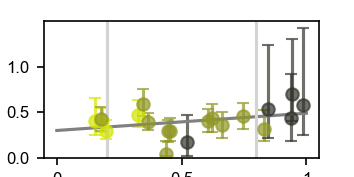

In [46]:
import numpy as np
import matplotlib.pyplot as plt

# --- Plot setup ---
cm_to_inch = 1 / 2.54
fig_width_cm = 6
fig_height_cm = 3

fig, ax = plt.subplots(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)

all_x = []
all_y = []

j = 0
for group_name, indices in index_groups.items():
    color = group_colors[j]
    print(group_name)

    y = [vfish_med[i] for i in indices]
    norm_fractions_bouts_array = fractions_bouts_list
    x = [norm_fractions_bouts_array[i] for i in indices]
    yerr = np.array([
        [vfish_iqm[i] for i in indices],
        [vfish_iqp[i] for i in indices]
    ])

    ax.errorbar(
        x, y,
        yerr=yerr,
        fmt='o',
        color=color,
        ecolor=color,
        elinewidth=1.5,
        capsize=3,
        label=group_name,
        alpha=0.7
    )

    all_x.extend(x)
    all_y.extend(y)
    j += 1

# --- Linear fit: y = a·x + b ---
all_x = np.array(all_x)
v_target = np.array(all_y)

coeffs = np.polyfit(all_x, v_target, 1)  # degree 1 for linear
a, b = coeffs
print(f"Linear fit: y = {a:.3f}·x + {b:.3f}")

# Generate fit line
x_fit = np.linspace(0, 1, 200)
y_fit = a * x_fit + b
ax.plot(x_fit, y_fit, '-', color='gray', linewidth=1.5, label='linear fit')

# --- Final formatting ---
ax.set_ylabel(r'$v^{*}$ (cm/s)')
ax.set_xlabel(r'intermittency index $\eta$')
ax.set_xticks([0, 0.5, 1], [0, 0.5, 1])
ax.set_ylim([0, 15])
ax.set_yticks([0, 5, 10], [0.0, 0.5, 1.0])

ax.axvline(0.2, color='lightgray')
ax.axvline(0.8, color='lightgray')
#ax.legend()

fig.savefig(os.path.join(path_figures, "Fig_S7c_target_speed_eta_all_fish.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_S7c_target_speed_eta_all_fish.pdf"), format="pdf", bbox_inches='tight', dpi=200)
plt.show()

# STATISTICS

In [47]:
from scipy import stats
print('#####---Spearman rank correlation coefficient---#####')


print('___eta - (vmax)')
res = stats.spearmanr(np.array(v_max), np.array(idx_bout))
print('spearmanr =', res.correlation)
print('pval =', res.pvalue)

print('___age - (vmax)')
res = stats.spearmanr(np.array(v_max), np.array(age))
print('spearmanr =', res.correlation)
print('pval =', res.pvalue)

#####---Spearman rank correlation coefficient---#####
___eta - (vmax)
spearmanr = 0.7172932330827068
pval = 0.0003711409336667313
___age - (vmax)
spearmanr = 0.6281267060146991
pval = 0.003020532373772672


In [48]:
"""
Functions for calculating the statistical significant differences between two dependent or independent correlation
coefficients.
The Fisher and Steiger method is adopted from the R package http://personality-project.org/r/html/paired.r.html
and is described in detail in the book 'Statistical Methods for Psychology'
The Zou method is adopted from http://seriousstats.wordpress.com/2012/02/05/comparing-correlations/
Credit goes to the authors of above mentioned packages!
Author: Philipp Singer (www.philippsinger.info)

------------------------------------------------------------
README.md:
CorrelationStats
This Python script enables you to compute statistical significance tests on both dependent and independent correlation coefficients. For each case two methods to choose from are available.

For details, please refer to: http://www.philippsinger.info/?p=347
#copied from on 4/24/2015 from https://github.com/psinger/CorrelationStats/blob/master/corrstats.py
"""

import numpy as np
from scipy.stats import t, norm
from math import atanh, pow
from numpy import tanh

def rz_ci(r, n, conf_level = 0.95):
    zr_se = pow(1/(n - 3), .5)
    moe = norm.ppf(1 - (1 - conf_level)/float(2)) * zr_se
    zu = atanh(r) + moe
    zl = atanh(r) - moe
    return tanh((zl, zu))

def rho_rxy_rxz(rxy, rxz, ryz):
    num = (ryz-1/2.*rxy*rxz)*(1-pow(rxy,2)-pow(rxz,2)-pow(ryz,2))+pow(ryz,3)
    den = (1 - pow(rxy,2)) * (1 - pow(rxz,2))
    return num/float(den)

def dependent_corr(xy, xz, yz, n, twotailed=True, conf_level=0.95, method='steiger'):
    """
    Calculates the statistic significance between two dependent correlation coefficients
    @param xy: correlation coefficient between x and y
    @param xz: correlation coefficient between x and z
    @param yz: correlation coefficient between y and z
    @param n: number of elements in x, y and z
    @param twotailed: whether to calculate a one or two tailed test, only works for 'steiger' method
    @param conf_level: confidence level, only works for 'zou' method
    @param method: defines the method uses, 'steiger' or 'zou'
    @return: t and p-val
    """
    if method == 'steiger':
        d = xy - xz
        determin = 1 - xy * xy - xz * xz - yz * yz + 2 * xy * xz * yz
        av = (xy + xz)/2
        cube = (1 - yz) * (1 - yz) * (1 - yz)

        t2 = d * np.sqrt((n - 1) * (1 + yz)/(((2 * (n - 1)/(n - 3)) * determin + av * av * cube)))
        p = 1 - t.cdf(abs(t2), n - 2)

        if twotailed:
            p *= 2

        return t2, p
    elif method == 'zou':
        L1 = rz_ci(xy, n, conf_level=conf_level)[0]
        U1 = rz_ci(xy, n, conf_level=conf_level)[1]
        L2 = rz_ci(xz, n, conf_level=conf_level)[0]
        U2 = rz_ci(xz, n, conf_level=conf_level)[1]
        rho_r12_r13 = rho_rxy_rxz(xy, xz, yz)
        lower = xy - xz - pow((pow((xy - L1), 2) + pow((U2 - xz), 2) - 2 * rho_r12_r13 * (xy - L1) * (U2 - xz)), 0.5)
        upper = xy - xz + pow((pow((U1 - xy), 2) + pow((xz - L2), 2) - 2 * rho_r12_r13 * (U1 - xy) * (xz - L2)), 0.5)
        return lower, upper
    else:
        raise Exception('Wrong method!')


In [49]:
# Inputs
v_max = np.array(v_max)
idx_bout = np.array(idx_bout)
age = np.array(age)
n = len(v_max)

# Spearman correlations
r_xy = stats.spearmanr(v_max, idx_bout).correlation   # v_max vs idx_bout
r_xz = stats.spearmanr(v_max, age).correlation        # v_max vs age
r_yz = stats.spearmanr(idx_bout, age).correlation     # idx_bout vs age

t_stat, p_val = dependent_corr(r_xy, r_xz, r_yz, n, method='steiger')

print("### Steiger’s test (dependent correlations) ###")
print(f"t = {t_stat:.3f}")
print(f"p = {p_val:.5f}")

### Steiger’s test (dependent correlations) ###
t = 0.730
p = 0.47455
